# Optimizing the borehole positions

The positions of the boreholes are free: `Coordinates.from_points` takes any list of (x, y) heads.
This notebook places the twelve boreholes of `demo_project.py` anywhere in a 30 × 20 m lot, at
least 4 m apart, so that the coldest entering fluid temperature of a 25-year simulation is as warm
as possible. The search is a plain evolutionary one: each generation perturbs the best layout found
so far in eight ways, and `run_many` simulates the eight candidates together. It is the notebook
version of `field_layout_optimization.py`.

Run it from the `examples` folder, with the executable and a licence (see
[Installation](../docs/install.md)).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pyghe as ga
import ghestyle as ghe
from demo_project import make_project
from field_layout_optimization import feasible

ghe.use()

## The problem

A layout is a (12, 2) array of heads. It is feasible if every head is inside the lot and no two are
closer than 4 m. The starting point is the 6 m grid of the project, centred in the lot.

In [2]:
lot = (30.0, 20.0)                                   # m, easting × northing
minimum_distance = 4.0                               # m between two boreholes
generations, children = 20, 8
rng = np.random.default_rng(1)

p = make_project()
start = ga.Coordinates.rectangle(nx=4, ny=3, spacing=6.0)
first = np.column_stack([start.x, start.y]) + [6.0, 4.0]
best = first.copy()

def variant(xy):
    q = p.copy()
    q.ground_heat_exchanger.coordinates = ga.Coordinates.from_points(xy)
    return q

best_eft = variant(best).simulate().summary.minimum_eft
history = [best_eft]
print(f"6 m grid: minimum EFT {best_eft:5.2f} °C")

6 m grid: minimum EFT  0.59 °C


## The search

Each child moves a few boreholes by a random step. When no child beats the best layout, the step
shrinks, so the search starts by exploring and ends by polishing.

In [3]:
step = 4.0                                           # m, standard deviation of a move
for generation in range(generations):
    candidates = []
    while len(candidates) < children:
        xy = best.copy()
        moved = rng.random(len(xy)) < 0.35               # each borehole moves with probability 0.35
        moved[rng.integers(len(xy))] = True
        xy[moved] += rng.normal(0, step, (moved.sum(), 2))
        if feasible(xy, lot, minimum_distance):
            candidates.append(xy)
    results = ga.run_many([variant(xy) for xy in candidates], "simulate")
    temperatures = [r.summary.minimum_eft for r in results]
    k = int(np.argmax(temperatures))
    if temperatures[k] > best_eft:
        best, best_eft = candidates[k], temperatures[k]
    else:
        step *= 0.8
    history.append(best_eft)
    print(f"generation {generation + 1:2d}: minimum EFT {best_eft:5.2f} °C")

generation  1: minimum EFT  0.74 °C


generation  2: minimum EFT  0.91 °C


generation  3: minimum EFT  0.96 °C


generation  4: minimum EFT  1.01 °C


generation  5: minimum EFT  1.08 °C


generation  6: minimum EFT  1.09 °C


... (10 outputs left out)

generation 17: minimum EFT  1.25 °C


generation 18: minimum EFT  1.27 °C


generation 19: minimum EFT  1.30 °C


generation 20: minimum EFT  1.31 °C


## Result

The boreholes move to the edge of the lot, where they interfere the least. The gain is about
0.7 K on the coldest hour, with the same total length.

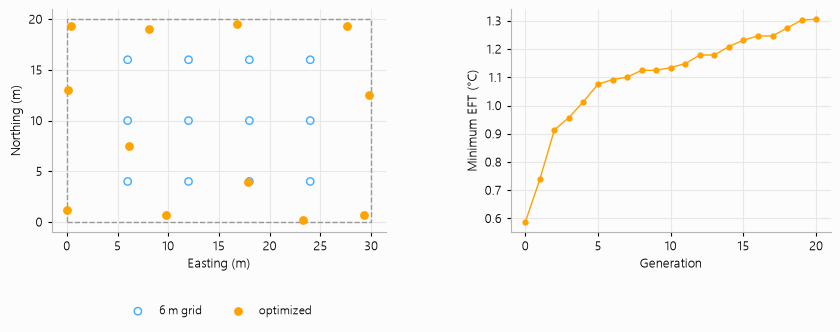

In [4]:
fig, (left, right) = plt.subplots(1, 2, figsize=(8.6, 3.2), gridspec_kw={"width_ratios": [1.5, 1]})
left.add_patch(plt.Rectangle((0, 0), *lot, fill=False, edgecolor="0.6", linestyle="--"))
left.scatter(*first.T, s=28, facecolor="none", edgecolor=ghe.BLUE, label="6 m grid")
left.scatter(*best.T, s=28, color=ghe.ORANGE, label="optimized")
left.set_aspect("equal")
ghe.axis_titles(left, "Easting (m)", "Northing (m)")
left.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2)
right.plot(range(generations + 1), history, color=ghe.ORANGE, marker="o", markersize=3.5)
ghe.axis_titles(right, "Generation", "Minimum EFT (°C)")
plt.show()

## Keeping the layout

The optimized field is an ordinary project: save it, and open it in GHE Analysis to see the
borehole layout and the thermal plume.

```python
best_project = variant(best)
best_project.save("optimized_layout.ghe")
```